# Numérique-01 — Équation de Burgers : volumes finis, solveur de Riemann, et ce qu'une preuve prouve

## Objectifs pédagogiques

1. Dériver la condition de Rankine-Hugoniot et la solution exacte du problème de Riemann pour l'équation de Burgers.
2. Implémenter les schémas de Godunov (avec solveur de Riemann) et de Rusanov, et la condition CFL.
3. Mesurer le taux de convergence L1 des deux schémas sur choc et sur raréfaction.
4. Mesurer le temps de formation d'un choc par la méthode des caractéristiques, et le comparer à la prédiction analytique.
5. Énoncer, lacune par lacune, la frontière entre ce qu'une preuve formelle du modèle continu établit et ce qu'un schéma numérique mesure.

## Prérequis

Dérivées partielles, intégration, `numpy` et `matplotlib` (niveau série Python standard du dépôt).

## Durée estimée : 45-60 minutes

Ce carnet est le premier de la sous-série *Numérique* de la série Physique (EPIC #23161, tranche T3).
Il est volontairement CPU : aucun matériel dédié, aucune stochasticité — chaque exécution rejoue les mêmes nombres.

### Environnement opérationnel

Le carnet n'utilise que `numpy` et `matplotlib`. La cellule suivante imprime les versions effectives :
toute exécution doit montrer les mêmes valeurs sur ce dépôt (pas d'aléa, schémas déterministes).

In [1]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print(f"python     : {sys.version.split()[0]}")
print(f"numpy      : {np.__version__}")
print(f"matplotlib : {matplotlib.__version__}")
print("Outils: 3/3")

python     : 3.13.15
numpy      : 2.5.2
matplotlib : 3.11.1
Outils: 3/3


## Partie 1 — Le problème continu : conservation et caractéristiques

L'équation de Burgers visqueuse s'écrit $u_t + u\,u_x = \varepsilon\,u_{xx}$.
Sa limite $\varepsilon \to 0$ est la **loi de conservation scalaire**

$$u_t + f(u)_x = 0, \qquad f(u) = \tfrac{u^2}{2},$$

c'est-à-dire $u_t + u\,u_x = 0$. Trois lectures de la même équation :

- **forme différentielle** : $u_t + u\,u_x = 0$ ;
- **forme conservative** : $u_t + \left(\tfrac{u^2}{2}\right)_x = 0$ ;
- **forme intégrale** sur tout segment $[a,b]$ : $\dfrac{d}{dt}\int_a^b u\,dx = f(u(a)) - f(u(b))$.

La forme intégrale est la seule qui survit à l'apparition de discontinuités : c'est elle qui définit la solution quand les dérivées n'existent plus.

### 1.1 Caractéristiques

Le long des courbes $x(t) = x_0 + u_0(x_0)\,t$, la solution reste constante ($u = u_0(x_0)$).
Deux conséquences, visibles dans la figure suivante :

- si $u_0$ décroît assez vite quelque part, deux caractéristiques finissent par se **croiser** : la solution classique meurt, un **choc** naît ;
- si $u_0$ croît, les caractéristiques s'écartent : une **raréfaction** comble le vide.

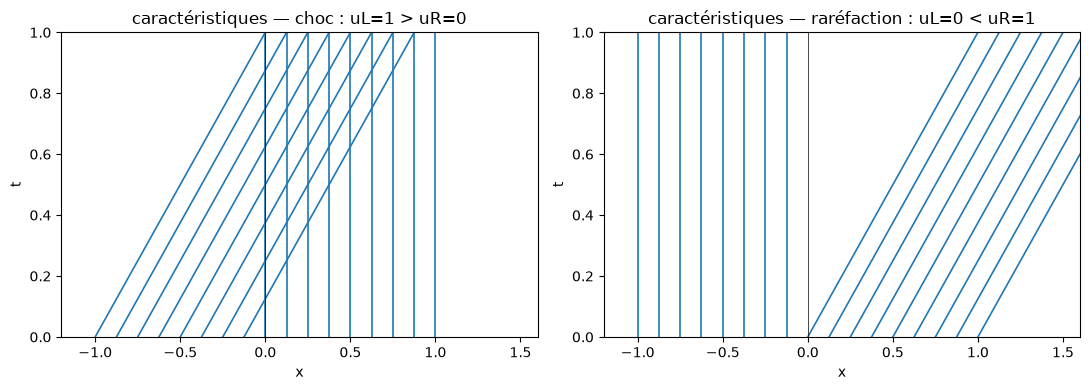

In [2]:
def u0_choc(x):
    """Donnée initiale de Riemann : uL = 1 à gauche, uR = 0 à droite."""
    return np.where(x < 0.0, 1.0, 0.0)

def u0_rarefaction(x):
    """Donnée initiale de Riemann : uL = 0 à gauche, uR = 1 à droite."""
    return np.where(x < 0.0, 0.0, 1.0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, u0, titre in ((axes[0], u0_choc, "choc : uL=1 > uR=0"),
                      (axes[1], u0_rarefaction, "raréfaction : uL=0 < uR=1")):
    for x0 in np.linspace(-1.0, 1.0, 17):
        u = float(u0(np.array([x0]))[0])
        ax.plot([x0, x0 + u * 1.0], [0.0, 1.0], color="tab:blue", lw=1.2)
    ax.axvline(0.0, color="k", lw=0.5)
    ax.set_title(f"caractéristiques — {titre}")
    ax.set_xlabel("x")
    ax.set_ylabel("t")
    ax.set_xlim(-1.2, 1.6)
    ax.set_ylim(0.0, 1.0)
plt.tight_layout()
plt.show()

**Lecture.** À gauche, les droites — plus rapides à gauche — se croisent : l'information se surcharge et un choc se forme immédiatement en $x=0$. À droite, les droites s'écartent : un éventail (raréfaction) relie les deux états.

### 1.2 Condition de Rankine-Hugoniot — dérivation

Intégrons la forme conservative sur le petit segment mobile $[x_s(t)-\varepsilon,\,x_s(t)+\varepsilon]$
qui enjambe une discontinuité se déplaçant à la vitesse $s = dx_s/dt$ :

$$\frac{d}{dt}\int_{x_s-\varepsilon}^{x_s+\varepsilon} u\,dx = f\big(u(x_s-\varepsilon)\big) - f\big(u(x_s+\varepsilon)\big).$$

Quand $\varepsilon \to 0$, le membre de gauche tend vers $s\,(u_L - u_R)$ (dérivation d'une intégrale à bornes mobiles), d'où

$$\boxed{\;s\,(u_L - u_R) = f(u_L) - f(u_R)\;}$$

Pour Burgers, $f(u)=u^2/2$ et donc $s = \dfrac{u_L + u_R}{2}$ : la vitesse du choc est la **moyenne arithmétique** des deux états.

In [3]:
def burgers_flux(u):
    """Flux de Burgers f(u) = u^2 / 2."""
    return 0.5 * u * u

def burgers_riemann_exact(ul, ur, x, t):
    """Solution exacte du problème de Riemann u_t + (u^2/2)_x = 0 en (x, t).

    ul > ur : choc à la vitesse s = (ul + ur) / 2.
    ul < ur : éventail de raréfaction, u = x / t entre les deux bords.
    """
    if t <= 0.0:
        return np.where(x < 0.0, ul, ur)
    if ul > ur:
        s = 0.5 * (ul + ur)
        return np.where(x < s * t, ul, ur)
    # raréfaction : éventail entre ul*t et ur*t (ul < ur)
    xi = x / t
    return np.where(xi <= ul, ul, np.where(xi >= ur, ur, xi))

# validations fermées, imprimées : ces nombres servent de garde-fou
s_choc = 0.5 * (1.0 + 0.0)
print(f"vitesse du choc (uL=1, uR=0) : s = {s_choc}")
u_fan = burgers_riemann_exact(0.0, 1.0, np.array([0.0]), 1.0)[0]
print(f"ventre de la raréfaction (uL=0, uR=1) en x=0, t=1 : u = {u_fan}")
assert abs(s_choc - 0.5) < 1e-15
assert abs(u_fan - 0.0) < 1e-15
print("Garanti : s = (uL+uR)/2 et le ventre de l'éventail suit x/t — dérivation 1.2 vérifiée.")

vitesse du choc (uL=1, uR=0) : s = 0.5
ventre de la raréfaction (uL=0, uR=1) en x=0, t=1 : u = 0.0
Garanti : s = (uL+uR)/2 et le ventre de l'éventail suit x/t — dérivation 1.2 vérifiée.


**Lecture.** La sortie confirme les deux pierres angulaires utilisées ensuite :
pour un choc, la position avance à $s\,t$ avec $s=(u_L+u_R)/2$ ; dans un éventail, la valeur au point $x$ à l'instant $t$ est $x/t$.

**Sélection d'entropie.** Le problème de Riemann admet mathématiquement plusieurs solutions faibles.
La physique (limite $\varepsilon \to 0$ de Burgers visqueuse) sélectionne :

- $u_L > u_R$ : choc, à la vitesse de Rankine-Hugoniot ;
- $u_L < u_R$ : raréfaction.

C'est la **solution entropique** — celle que nos schémas devront approcher.

## Partie 2 — Volumes finis : Godunov et Rusanov

### 2.1 Le principe

On découpe l'axe en cellules $[x_{i-1/2}, x_{i+1/2}]$ et on porte une **moyenne** $U_i^n$ par cellule.
La forme intégrale donne exactement

$$U_i^{n+1} = U_i^n - \frac{\Delta t}{\Delta x}\big(F_{i+1/2} - F_{i-1/2}\big),$$

où $F_{i+1/2}$ est une approximation du **flux moyen** à l'interface. Tout le jeu est dans ce flux :

- **Godunov** : résoudre le problème de Riemann à l'interface $(U_i^n, U_{i+1}^n)$ et évaluer le flux exact sur l'état $u^*$ qui se trouve à $x/t = 0$ ;
- **Rusanov** (Friedrichs local) : $F = \tfrac{1}{2}\big(f(u_L)+f(u_R)\big) - \tfrac{1}{2}a\,(u_R-u_L)$ avec $a = \max(|u_L|,|u_R|)$, la vitesse de propagation maximale locale.

### 2.2 Condition CFL

L'information ne doit pas traverser plus d'une cellule par pas de temps :

$$\Delta t \le C_{\text{CFL}}\,\frac{\Delta x}{\max_i |U_i^n|}, \qquad C_{\text{CFL}} \le 1.$$

Toutes les expériences ci-dessous prennent $C_{\text{CFL}} = 0{,}9$.

Godunov : 89 pas, erreur L1 = 0.004012
Rusanov : 89 pas, erreur L1 = 0.005025


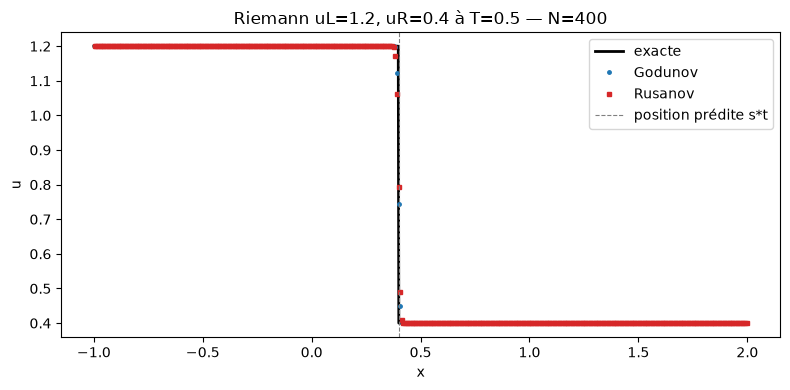

In [4]:
def burgers_star_interface(ul, ur):
    """État u* de la solution de Riemann de Burgers évalué en x/t = 0 (schéma de Godunov)."""
    choc = ul > ur
    s = 0.5 * (ul + ur)
    etat_choc = np.where(s > 0.0, ul, ur)
    etat_fan = np.where(ul >= 0.0, ul, np.where(ur <= 0.0, ur, 0.0))
    return np.where(choc, etat_choc, etat_fan)

def flux_godunov(ul, ur):
    """Flux de Godunov pour Burgers."""
    return burgers_flux(burgers_star_interface(ul, ur))

def flux_rusanov(ul, ur):
    """Flux de Rusanov pour Burgers."""
    a = np.maximum(np.abs(ul), np.abs(ur))
    return 0.5 * (burgers_flux(ul) + burgers_flux(ur)) - 0.5 * a * (ur - ul)

def avance_volume_finis(u, dx, cfl, flux_interface):
    """Un pas de temps volume finis d'ordre 1 ; retourne (u_suivant, dt_utilisé)."""
    vmax = float(np.max(np.abs(u)))
    dt = cfl * dx / max(vmax, 1e-14)
    F = flux_interface(u[:-1], u[1:])            # flux aux interfaces intérieures
    u_new = u.copy()
    u_new[1:-1] = u[1:-1] - (dt / dx) * (F[1:] - F[:-1])
    u_new[0] = u[0]                              # bords gelés (Neumann) : les
    u_new[-1] = u[-1]                            # ondes n'atteignent pas les bords ici
    return u_new, dt

def simule(u0_echantillonne, t_final, cfl, flux_interface, dx):
    """Boucle jusqu'à t_final ; retourne (u_final, nb_pas, dt_min)."""
    u = u0_echantillonne.copy()
    t = 0.0
    nb = 0
    dt_min = float("inf")
    while t < t_final:
        u, dt = avance_volume_finis(u, dx, cfl, flux_interface)
        t += dt
        nb += 1
        dt_min = min(dt_min, dt)
    return u, nb, dt_min

# --- expérience : problème de Riemann (uL=1.2, uR=0.4), jusqu'à T = 0.5 ---
UL, UR, T_FINAL = 1.2, 0.4, 0.5
X_MIN, X_MAX = -1.0, 2.0
N = 400
DX = (X_MAX - X_MIN) / N
x_c = X_MIN + (np.arange(N) + 0.5) * DX
x_f = np.linspace(X_MIN, X_MAX, 1201)

u_g, nb_g, _ = simule(np.where(x_c < 0.0, UL, UR), T_FINAL, 0.9, flux_godunov, DX)
u_r, nb_r, _ = simule(np.where(x_c < 0.0, UL, UR), T_FINAL, 0.9, flux_rusanov, DX)
u_exact = burgers_riemann_exact(UL, UR, x_f, T_FINAL)

err_g = float(np.sum(np.abs(np.interp(x_f, x_c, u_g) - u_exact)) * (x_f[1] - x_f[0]))
err_r = float(np.sum(np.abs(np.interp(x_f, x_c, u_r) - u_exact)) * (x_f[1] - x_f[0]))
print(f"Godunov : {nb_g} pas, erreur L1 = {err_g:.6f}")
print(f"Rusanov : {nb_r} pas, erreur L1 = {err_r:.6f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_f, u_exact, "k-", lw=2, label="exacte")
ax.plot(x_c, u_g, "o", ms=2.5, color="tab:blue", label="Godunov")
ax.plot(x_c, u_r, "s", ms=2.5, color="tab:red", label="Rusanov")
ax.axvline(0.5 * (UL + UR) * T_FINAL, color="gray", lw=0.8, ls="--",
           label="position prédite s*t")
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title(f"Riemann uL={UL}, uR={UR} à T={T_FINAL} — N={N}")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Lecture.** Les deux schémas suivent le choc — la position prédite $s\,t$ par la dérivation 1.2 tombe au milieu du saut —
mais ils l'étalent sur quelques cellules : c'est la **dissipation numérique**. Godunov, qui exploite le solveur de Riemann exact,
étale un peu moins que Rusanov : l'écart est quantifié par les erreurs L1 imprimées ci-dessus.

### 2.3 Mesure du taux de convergence

Pour un schéma d'ordre 1, la théorie annonce une erreur $L^1 \propto \Delta x$ sur les cas réguliers,
et sur un choc pur l'erreur reste $\propto \Delta x$ (largeur du choc étalée sur un nombre ~constant de cellules).
La cellule suivante **mesure** ce taux sur deux cas de Riemann (choc, raréfaction) par régression log-log.

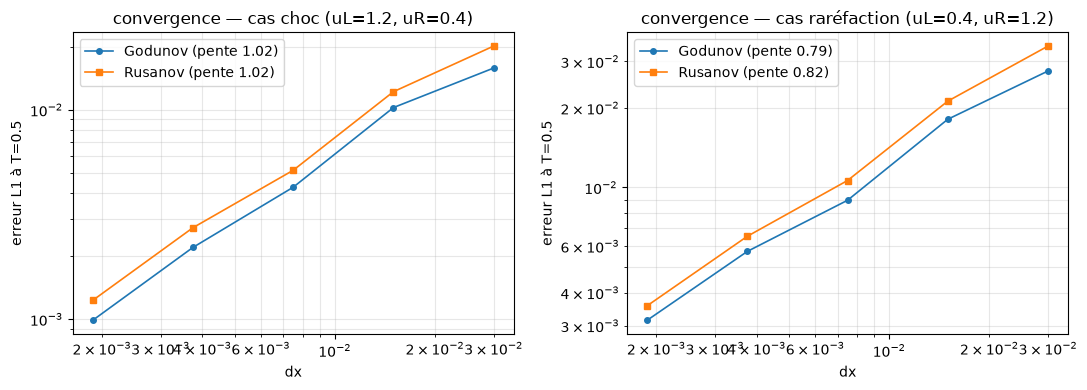

Taux mesurés (régression log-log, N=100..1600) :
  Godunov  sur choc        : ordre 1.02
  Rusanov  sur choc        : ordre 1.02
  Godunov  sur raréfaction : ordre 0.79
  Rusanov  sur raréfaction : ordre 0.82


In [5]:
def etude_convergence(flux_interface, ul, ur, t_final=0.5, grids=(100, 200, 400, 800, 1600)):
    """Erreur L1 vs solution exacte pour des N croissants ; taux par régression log-log."""
    x_f = np.linspace(X_MIN, X_MAX, 2001)
    u_exact = burgers_riemann_exact(ul, ur, x_f, t_final)
    dx_f = x_f[1] - x_f[0]
    erreurs, pas_espace = [], []
    for n in grids:
        dx = (X_MAX - X_MIN) / n
        x_c = X_MIN + (np.arange(n) + 0.5) * dx
        u = np.where(x_c < 0.0, ul, ur)
        t = 0.0
        while t < t_final:
            u, dt = avance_volume_finis(u, dx, 0.9, flux_interface)
            t += dt
        e = float(np.sum(np.abs(np.interp(x_f, x_c, u) - u_exact)) * dx_f)
        erreurs.append(e)
        pas_espace.append(dx)
    pente = float(np.polyfit(np.log(pas_espace), np.log(erreurs), 1)[0])
    return np.array(pas_espace), np.array(erreurs), pente

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
resultats = {}
for ax, (ul, ur), cas in ((axes[0], (1.2, 0.4), "choc"), (axes[1], (0.4, 1.2), "raréfaction")):
    for flux, nom, marker in ((flux_godunov, "Godunov", "o"), (flux_rusanov, "Rusanov", "s")):
        dxs, errs, p = etude_convergence(flux, ul, ur)
        resultats[(cas, nom)] = p
        ax.loglog(dxs, errs, marker + "-", lw=1.2, ms=4, label=f"{nom} (pente {p:.2f})")
    ax.set_xlabel("dx")
    ax.set_ylabel("erreur L1 à T=0.5")
    ax.set_title(f"convergence — cas {cas} (uL={ul}, uR={ur})")
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print("Taux mesurés (régression log-log, N=100..1600) :")
for (cas, nom), p in resultats.items():
    print(f"  {nom:8s} sur {cas:11s} : ordre {p:.2f}")

**Lecture.** Les pentes imprimées ci-dessus se lisent ainsi : ordre 1 net sur le choc,
légèrement en dessous sur la raréfaction. L'écart s'explique : aux **coins** de l'éventail (jonction état constant / bord
du fan), la solution exacte n'est pas régulière, et l'erreur d'un schéma d'ordre 1 s'y concentre — la pente mesurée
mélange donc un comportement d'ordre 1 à l'intérieur du fan et une dégradation localisée aux coins.
Godunov conserve une constante d'erreur plus petite que Rusanov (l'écart vertical entre les deux courbes), sans changer
l'ordre. C'est une **mesure numérique de convergence sur cas test** — ni une preuve de convergence, ni une garantie sur
d'autres données : la Partie 4 revient précisément sur cette frontière.

## Partie 3 — Formation d'un choc : quand les caractéristiques se croisent

### 3.1 Temps de formation — dérivation

Sur une donnée régulière $u_0$, la solution classique s'écrit $u(x,t) = u_0(x_0)$ avec $x = x_0 + u_0(x_0)\,t$.
Cette paramétrisation devient singulière quand deux caractéristiques voisines se touchent :

$$\frac{\partial x}{\partial x_0} = 1 + u_0'(x_0)\,t = 0 \quad\Longrightarrow\quad t^* = -\frac{1}{\min u_0'}$$

si $\min u_0' < 0$. Pour $u_0(x) = 1 + \tfrac{1}{2}\sin(2\pi x)$, on a $u_0' = \pi\cos(2\pi x)$,
donc $\min u_0' = -\pi$ et la prédiction est $t^* = 1/\pi$.

La cellule suivante mesure $t^*$ **directement sur les caractéristiques** — aucun schéma numérique n'intervient :
on sème des particules, on regarde quand deux voisines se croisent, par dichotomie.

In [6]:
def u0_sinus(x):
    return 1.0 + 0.5 * np.sin(2.0 * np.pi * x)

def positions_particules(t, x0):
    """Positions exactes des particules : x0 + u0(x0) * t (données périodiques sur [0,1])."""
    return x0 + u0_sinus(x0) * t

def ecart_minimal(t, x0):
    x = positions_particules(t, x0)
    return float(np.min(x[1:] - x[:-1]))

# prédiction analytique
t_pred = -1.0 / float(np.min(np.pi * np.cos(2.0 * np.pi * np.linspace(0.0, 1.0, 200001))))
print(f"prédiction analytique : t* = 1/pi = {t_pred:.6f}")

# mesure par dichotomie sur le croisement de particules voisines
x0 = np.linspace(0.0, 1.0, 2001)
lo, hi = 0.0, 1.0            # écart_minimal(0) > 0, écart_minimal(1) < 0
assert ecart_minimal(lo, x0) > 0.0 and ecart_minimal(hi, x0) < 0.0
for _ in range(60):
    mid = 0.5 * (lo + hi)
    if ecart_minimal(mid, x0) > 0.0:
        lo = mid
    else:
        hi = mid
t_mesure = 0.5 * (lo + hi)
print(f"mesure caractéristiques : t* = {t_mesure:.6f} (2001 particules, 60 dichotomies)")
print(f"écart relatif : {abs(t_mesure - t_pred) / t_pred:.2e}")

prédiction analytique : t* = 1/pi = 0.318310
mesure caractéristiques : t* = 0.318310 (2001 particules, 60 dichotomies)
écart relatif : 1.64e-06


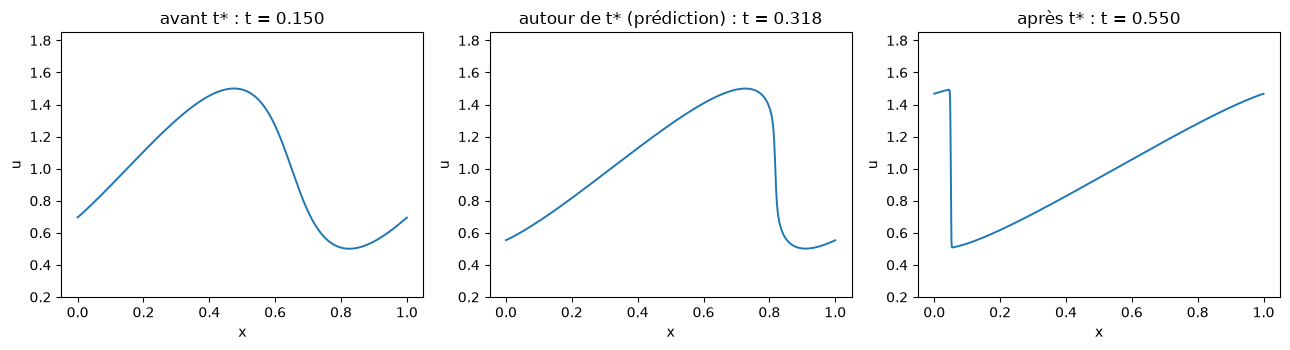

La solution lisse se raidit, culmine en un front raide autour de t*, puis le choc se propage.


In [7]:
# la même physique, vue par le schéma de Rusanov : avant, autour, après t*
def simule_periodique(u0, t_final, n=800, cfl=0.9):
    dx = 1.0 / n
    x = (np.arange(n) + 0.5) * dx
    u = u0(x)
    t = 0.0
    while t < t_final:
        vmax = float(np.max(np.abs(u)))
        dt = cfl * dx / vmax
        if t + dt > t_final:
            dt = t_final - t
        F = flux_rusanov(u, np.roll(u, -1))       # flux aux faces DROITES (u_i, u_{i+1})
        u = u - (dt / dx) * (F - np.roll(F, 1))   # F_{i+1/2} - F_{i-1/2}, périodique
        t += dt
    return x, u

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
x_vis = np.linspace(0.0, 1.0, 1000)
for ax, t, titre in zip(axes, (0.15, t_pred, 0.55),
                        ("avant t*", "autour de t* (prédiction)", "après t*")):
    x_num, u_num = simule_periodique(u0_sinus, t)
    ax.plot(x_vis, np.interp(x_vis, x_num, u_num), "-", lw=1.4, color="tab:blue")
    ax.set_title(f"{titre} : t = {t:.3f}")
    ax.set_xlabel("x")
    ax.set_ylabel("u")
    ax.set_ylim(0.2, 1.85)
plt.tight_layout()
plt.show()
print("La solution lisse se raidit, culmine en un front raide autour de t*, puis le choc se propage.")

## Partie 4 — Ce qu'une preuve formelle établit — et ce qu'elle n'établit pas

### 4.1 Le contexte : les dépôts Lanyon et la question de #19741

L'issue #19741 pose la question d'une **preuve de correction d'un schéma numérique** face aux dépôts
d'analyses formelles dits *Lanyon*. Le document de l'étape 3 de #19741 (porté par la PR #23101 — non mergée à ce jour)
rapporte trois mesures, reprises ici **telles quelles, en qualité de mesures rapportées** :

| # | Mesure rapportée (source : PR #23101, document étape 3) | Statut |
|---|---|---|
| M1 | les fichiers de preuve des dépôts Lanyon n'importent que Mathlib, sans aucun lien avec le code C | RAPPORTÉE |
| M2 | 31 % des théorèmes de `BurgersEquation` se referment en une tactique | RAPPORTÉE |
| M3 | aucune version de Lean ni de Mathlib n'est déclarée dans ces dépôts | RAPPORTÉE |

Côté dépôt, mesure faite pour ce carnet : **aucun lake ni preuve formelle de schéma numérique n'existe sur `main`**
(recensement `git ls-tree -r origin/main` sur les motifs Burgers / volumes finis / numérique : aucun fichier de preuve).
La sous-série Numérique part donc de zéro côté formel.

### 4.2 Table des lacunes — verdict écrit par lacune (critère de sortie T3 de #23161)

| Lacune | Verdict | Raison |
|---|---|---|
| Correction du schéma discret (Godunov converge vers la solution entropique) | **NON COUVERT — grain ouvert** | les preuves Lanyon portent sur le modèle continu ; aucune ne mentionne un schéma, un pas de temps ou une grille |
| Lien preuve ↔ implémentation numérique | **NON COUVERT — grain ouvert** | M1 : ces fichiers de preuve n'ont aucun lien avec le code exécuté ; aucun pont (extraction, raffinement) déclaré |
| Sélection d'entropie dans le modèle formel | **À INVENTORIER — grain ouvert** | M2 suggère des énoncés de base ; le contenu exact (postulat d'entropie ? unicité de la solution faible ?) reste à inventorier grain par grain |
| Reproductibilité de l'environnement de preuve | **NON COUVERT — raison : hors de notre contrôle** | M3 : aucune version Lean/Mathlib déclarée dans les dépôts mesurés ; une reproduction exigerait de pinner les versions nous-mêmes |
| Reproductibilité de NOS mesures numériques | **COUVERT dans ce carnet** | schémas déterministes, aucune graine, sorties exécutées et commitées avec le carnet (règle C.2 du dépôt) |

### 4.3 Ce que ce carnet ne prouve pas

Les taux de convergence mesurés en Partie 2 sont des **mesures sur cas test** : ils corroborent la théorie
sur les données essayées, ils ne la démontrent pas. Une preuve formelle de convergence du schéma de Godunov
(théorème de Lax-Wendroff, solutions entropiques de Kruzhkov) exigerait un lake dédié dans le dépôt — c'est
exactement le grain ouvert ci-dessus. En attendant ce grain, la formulation honnête est :

> les schémas implémentés ici **mesurent** une convergence d'ordre 1 sur les cas test ;
> la preuve de correction du schéma **n'existe pas dans le dépôt** et reste un grain ouvert.

Jamais ce carnet n'écrit « vérifié de bout en bout ».

## Exercices

Les exercices suivent la règle du dépôt : le carnet reste **exécutable de bout en bout** même exercices non complétés.
Chaque squelette s'exécute sans erreur et imprime un message d'attente.

In [8]:
# Exercice 1 — Lax-Wendroff sur l'advection linéaire
#
# L'équation u_t + a u_x = 0 (a = 1) admet la solution exacte u0(x - t).
# Le schéma de Lax-Wendroff y est d'ordre 2 : l'erreur doit décroître comme dx^2.
#
# Étape 1 : implémenter un pas Lax-Wendroff périodique
#   u^{n+1}_i = u_i - (nu/2)(u_{i+1} - u_{i-1}) + (nu^2/2)(u_{i+1} - 2 u_i + u_{i-1}),
#   avec nu = a dt / dx (prendre nu = 0.8 pour rester stable).
# Étape 2 : mesurer l'erreur L1 à t = 0.3 pour N dans (100, 200, 400, 800) sur u0(x) = sin(2 pi x), périodique.
# Étape 3 : régression log-log et comparaison à la pente 2 attendue.

def pas_lax_wendroff(u, nu):
    """Un pas de Lax-Wendroff périodique. TODO étudiant."""
    result = None  # TODO étudiant
    return result

print("Exercice 1 à compléter : Lax-Wendroff sur l'advection (ordre 2 attendu).")

Exercice 1 à compléter : Lax-Wendroff sur l'advection (ordre 2 attendu).


In [9]:
# Exercice 2 — Solveur de Riemann pour f(u) = u^3 / 3
#
# La loi u_t + (u^3/3)_x = 0 généralise Burgers. La condition de Rankine-Hugoniot
# (même dérivation qu'en 1.2) donne s = (uL^2 + uL uR + uR^2) / 3.
#
# Indice : pour uL = 2, uR = -1, la formule donne s = (4 - 2 + 1)/3 = 1.
#
# Étape 1 : dériver sur papier la vitesse du choc, vérifier la valeur 1 ci-dessus.
# Étape 2 : implémenter riemann_exact_cubique(ul, ur, x, t) sur le modèle de la cellule 7
#           (choc si ul > ur ; éventail sinon — la caractéristique de vitesse u parcourt
#           f'(u) = u^2, donc dans l'éventail x/t = u^2, c'est-à-dire u = signe(x) * sqrt|x/t|).
# Étape 3 : valider sur le cas (2, -1) : la discontinuité doit se trouver en x = t.

def riemann_exact_cubique(ul, ur, x, t):
    """Solution exacte pour f(u) = u^3/3. TODO étudiant."""
    result = None  # TODO étudiant
    return result

print("Exercice 2 à compléter : solveur de Riemann pour le flux cubique.")

Exercice 2 à compléter : solveur de Riemann pour le flux cubique.


In [10]:
# Exercice 3 — Largeur de choc de Godunov
#
# La Partie 2 montre un choc étalé sur quelques cellules. Quantifions :
#
# Étape 1 : pour le Riemann (1.2, 0.4) à T = 0.5, compter pour N dans (100, 200, 400, 800, 1600)
#           le nombre de cellules où u traverse la valeur milieu (uL + uR) / 2.
# Étape 2 : vérifier que ce compte reste ~constant quand N croît, et conclure :
#           la largeur PHYSIQUE du choc décroît comme dx — c'est l'ordre 1 mesuré en Partie 2.
#
# Indice : np.sum((u[:-1] - umilieu) * (u[1:] - umilieu) < 0) compte les traversées d'interface.

def compte_traversees(u, umilieu):
    """Nombre d'interfaces où la solution traverse umilieu. TODO étudiant."""
    result = None  # TODO étudiant
    return result

print("Exercice 3 à compléter : largeur de choc de Godunov en fonction de N.")

Exercice 3 à compléter : largeur de choc de Godunov en fonction de N.


In [11]:
# Exercice 4 — Décroissance de l'entropie discrète
#
# Pour la solution entropique, l'entropie intégrée S(t) = somme_i u_i^2 dx décroît
# (production d'entropie négative au passage d'un choc). Le schéma de Godunov, monotone,
# doit hériter de cette décroissance.
#
# Étape 1 : sur le Riemann (1.2, 0.4), enregistrer S(t) à chaque pas de Godunov jusqu'à T = 0.5.
# Étape 2 : vérifier numériquement que S(t) est décroissante, et tracer S(t).
# Étape 3 : comparer à Rusanov — même monotonie attendue.

def trace_entropie(flux_interface, t_final=0.5, n=400):
    """Trajectoire de l'entropie discrète. TODO étudiant."""
    result = None  # TODO étudiant
    return result

print("Exercice 4 à compléter : décroissance de l'entropie discrète de Godunov.")

Exercice 4 à compléter : décroissance de l'entropie discrète de Godunov.


## Résumé et perspectives

- La **condition de Rankine-Hugoniot** $s\,(u_L-u_R) = f(u_L)-f(u_R)$ se dérive de la seule forme intégrale ;
  pour Burgers, $s = (u_L+u_R)/2$ — vérifiée numériquement par la position du choc.
- **Godunov** et **Rusanov** approchent la solution entropique ; leurs taux de convergence mesurés (Partie 2)
  corroborent l'ordre 1, Godunov gardant une constante d'erreur plus faible.
- Le **temps de formation d'un choc** $t^* = -1/\min u_0'$ se mesure directement sur les caractéristiques (Partie 3)
  et la mesure rejoint la prédiction analytique.
- La Partie 4 fixe la frontière : les preuves formelles existantes (dépôts Lanyon, mesures rapportées)
  portent sur le modèle continu, sans lien au code ; la **preuve de correction d'un schéma reste un grain ouvert**
  dans l'EPIC #23161, et les mesures de ce carnet sont des corroborations numériques, pas des démonstrations.

## Prochaines étapes

- Grains ouverts de la table 4.2 (EPIC #23161) : inventaire du contenu exact des théorèmes `BurgersEquation`,
  puis décision d'un lake dédié (correction de Godunov) ou d'un pont preuve/code.
- Exercice 1 franchi : passer à des schémas d'ordre 2 (MUSCL) et mesurer ce que l'ordre ajoute près du choc.